## Movement patterns across vessel types (Flag 20)

### Dataset Overview
Constructed cargo, tanker, and fishing trajectories around Skagen: cargo and tankers use long continuous passage lanes around the headland, while fishing voyages connect Hirtshals, Skagen, and Frederikshavn through alternating direct-transit and low-speed manoeuvring phases before returning to harbour.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how movement patterns differ among vessel types operating in the same maritime area.

Role: Maritime traffic analyst


Category: movement patterns across vessel types

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do spatial movement patterns differ by vessel type?

#### Analysis action

Compare long passages around Skagen with harbour-connected localized operating regions.

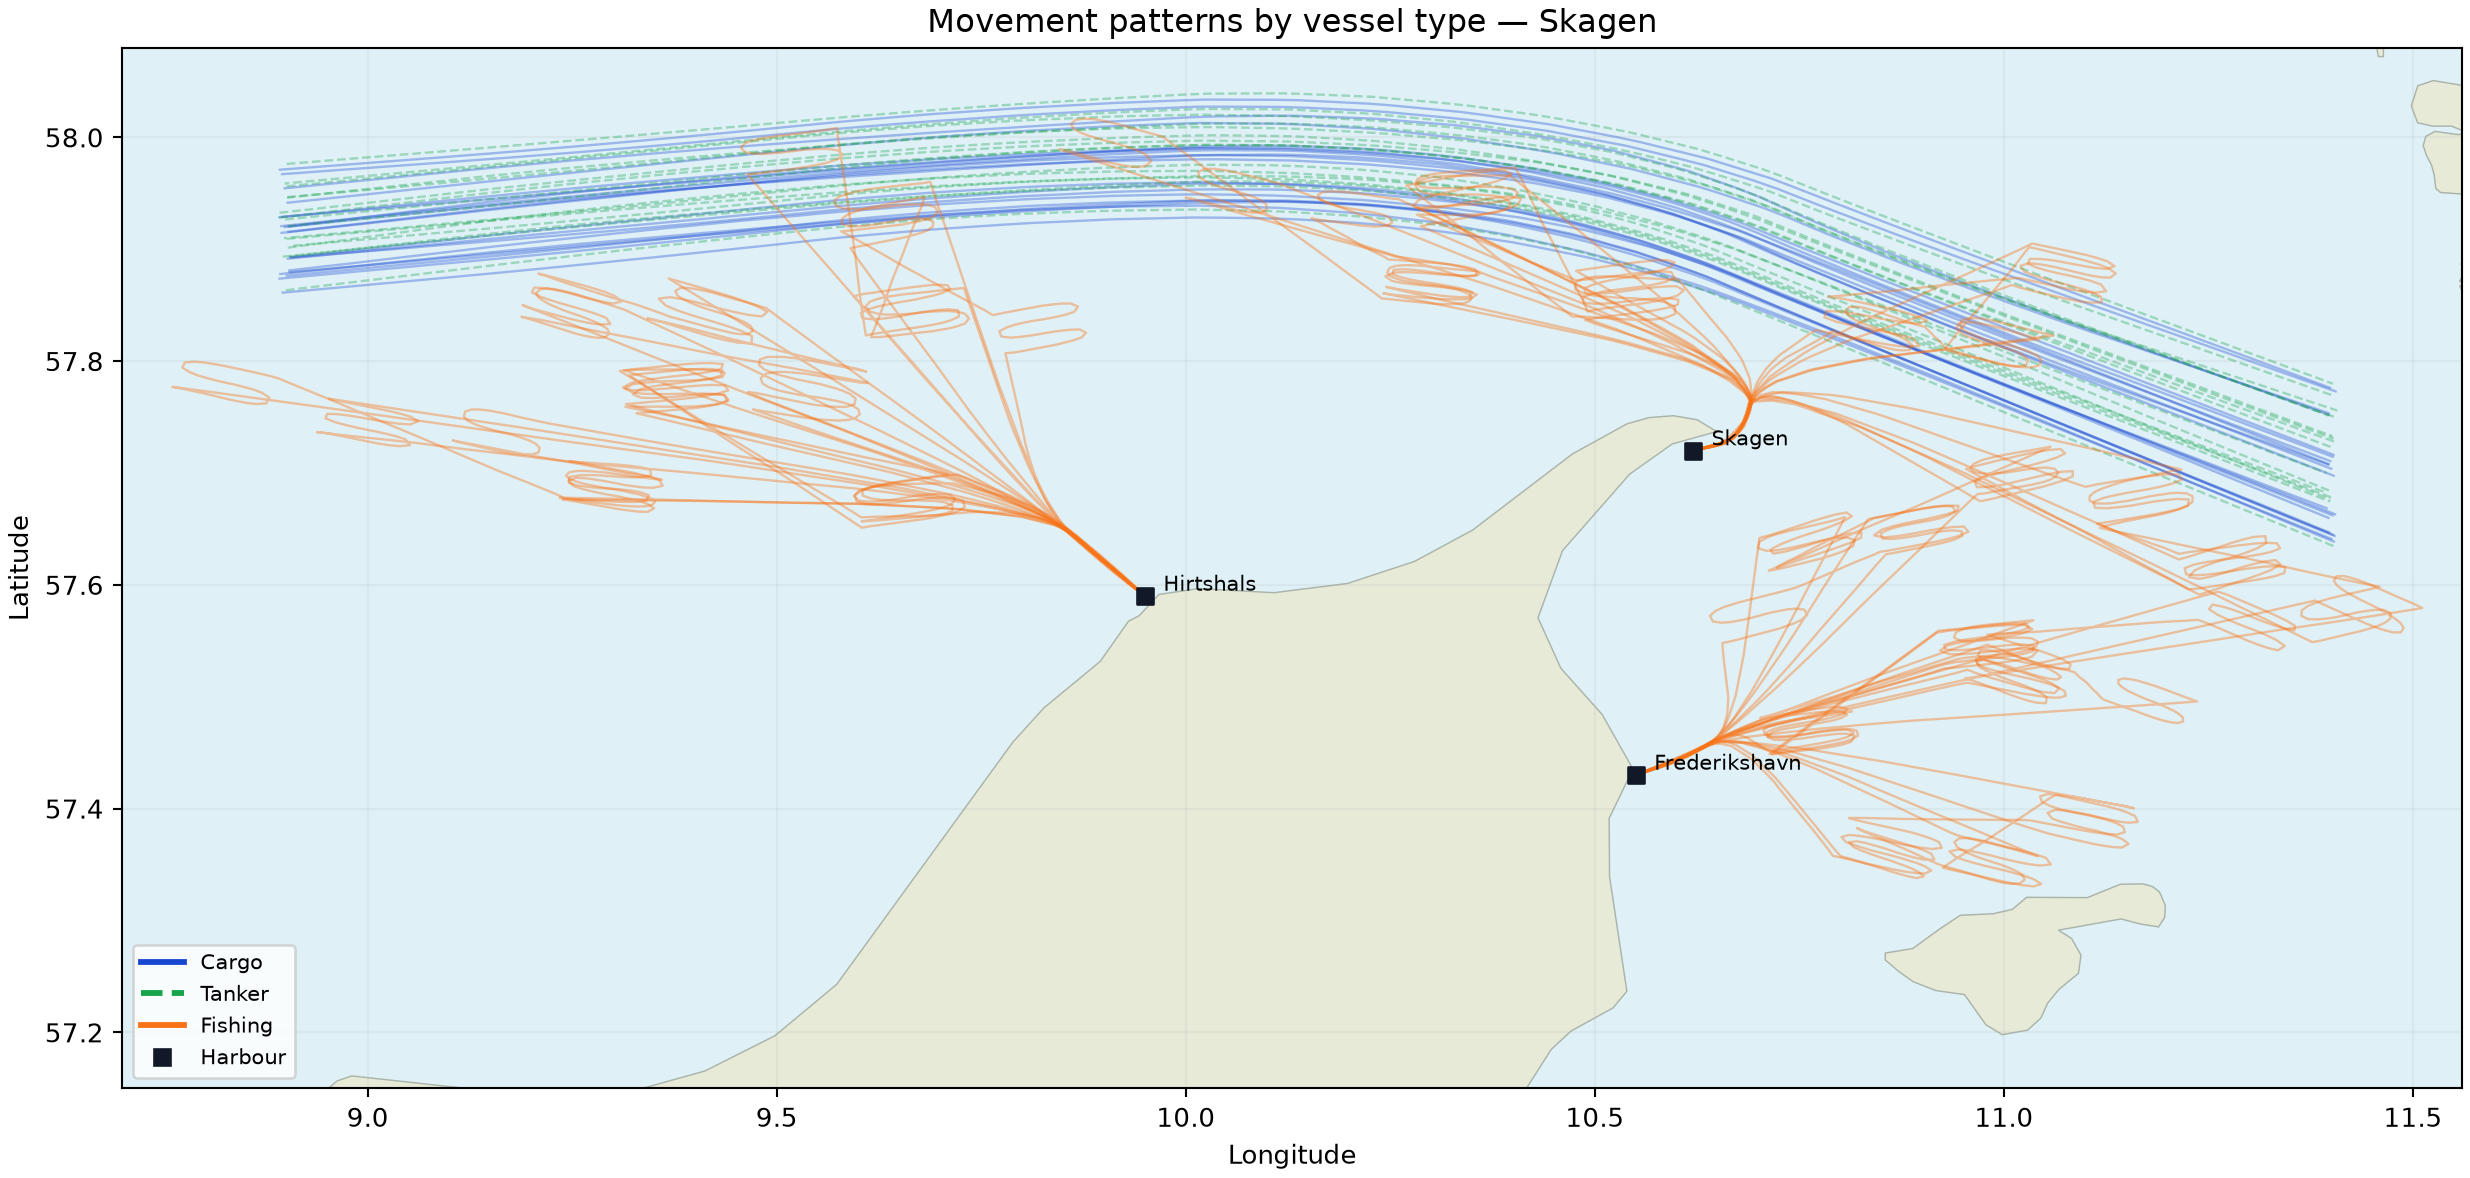

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on="vessel_id"); print(df.groupby("ship_type").trajectory_id.nunique())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/vessel_type_overview.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_type_spatial_pattern",
  "insight": "Cargo and tanker vessels mainly make long, continuous passages across the area, while fishing vessels repeatedly remain within smaller local operating regions before continuing their trips.",
  "insight_value": {
    "trajectory_counts": {
      "Fishing": 36,
      "Cargo": 20,
      "Tanker": 16
    },
    "median_fishing_local_phase_share": 0.479
  },
  "plot": {
    "plot_type": "type_colored_trajectory_map",
    "title": "Movement Geometry by Vessel Type",
    "file": "visualizations/vessel_type_overview.png",
    "description": "Compare long passages around Skagen with harbour-connected localized operating regions."
  },
  "question": "How do spatial movement patterns differ by vessel type?",
  "actionable_insight": "Compare long passages around Skagen with harbour-connected localized operating regions.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on=\"vessel_id\"); print(df.groupby(\"ship_type\").trajectory_id.nunique())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do speed and direction dynamics differ among vessel types?

#### Analysis action

Show the actual five-stage fishing status sequence along trajectory distance and compare trajectory-level successive COG changes across vessel types.

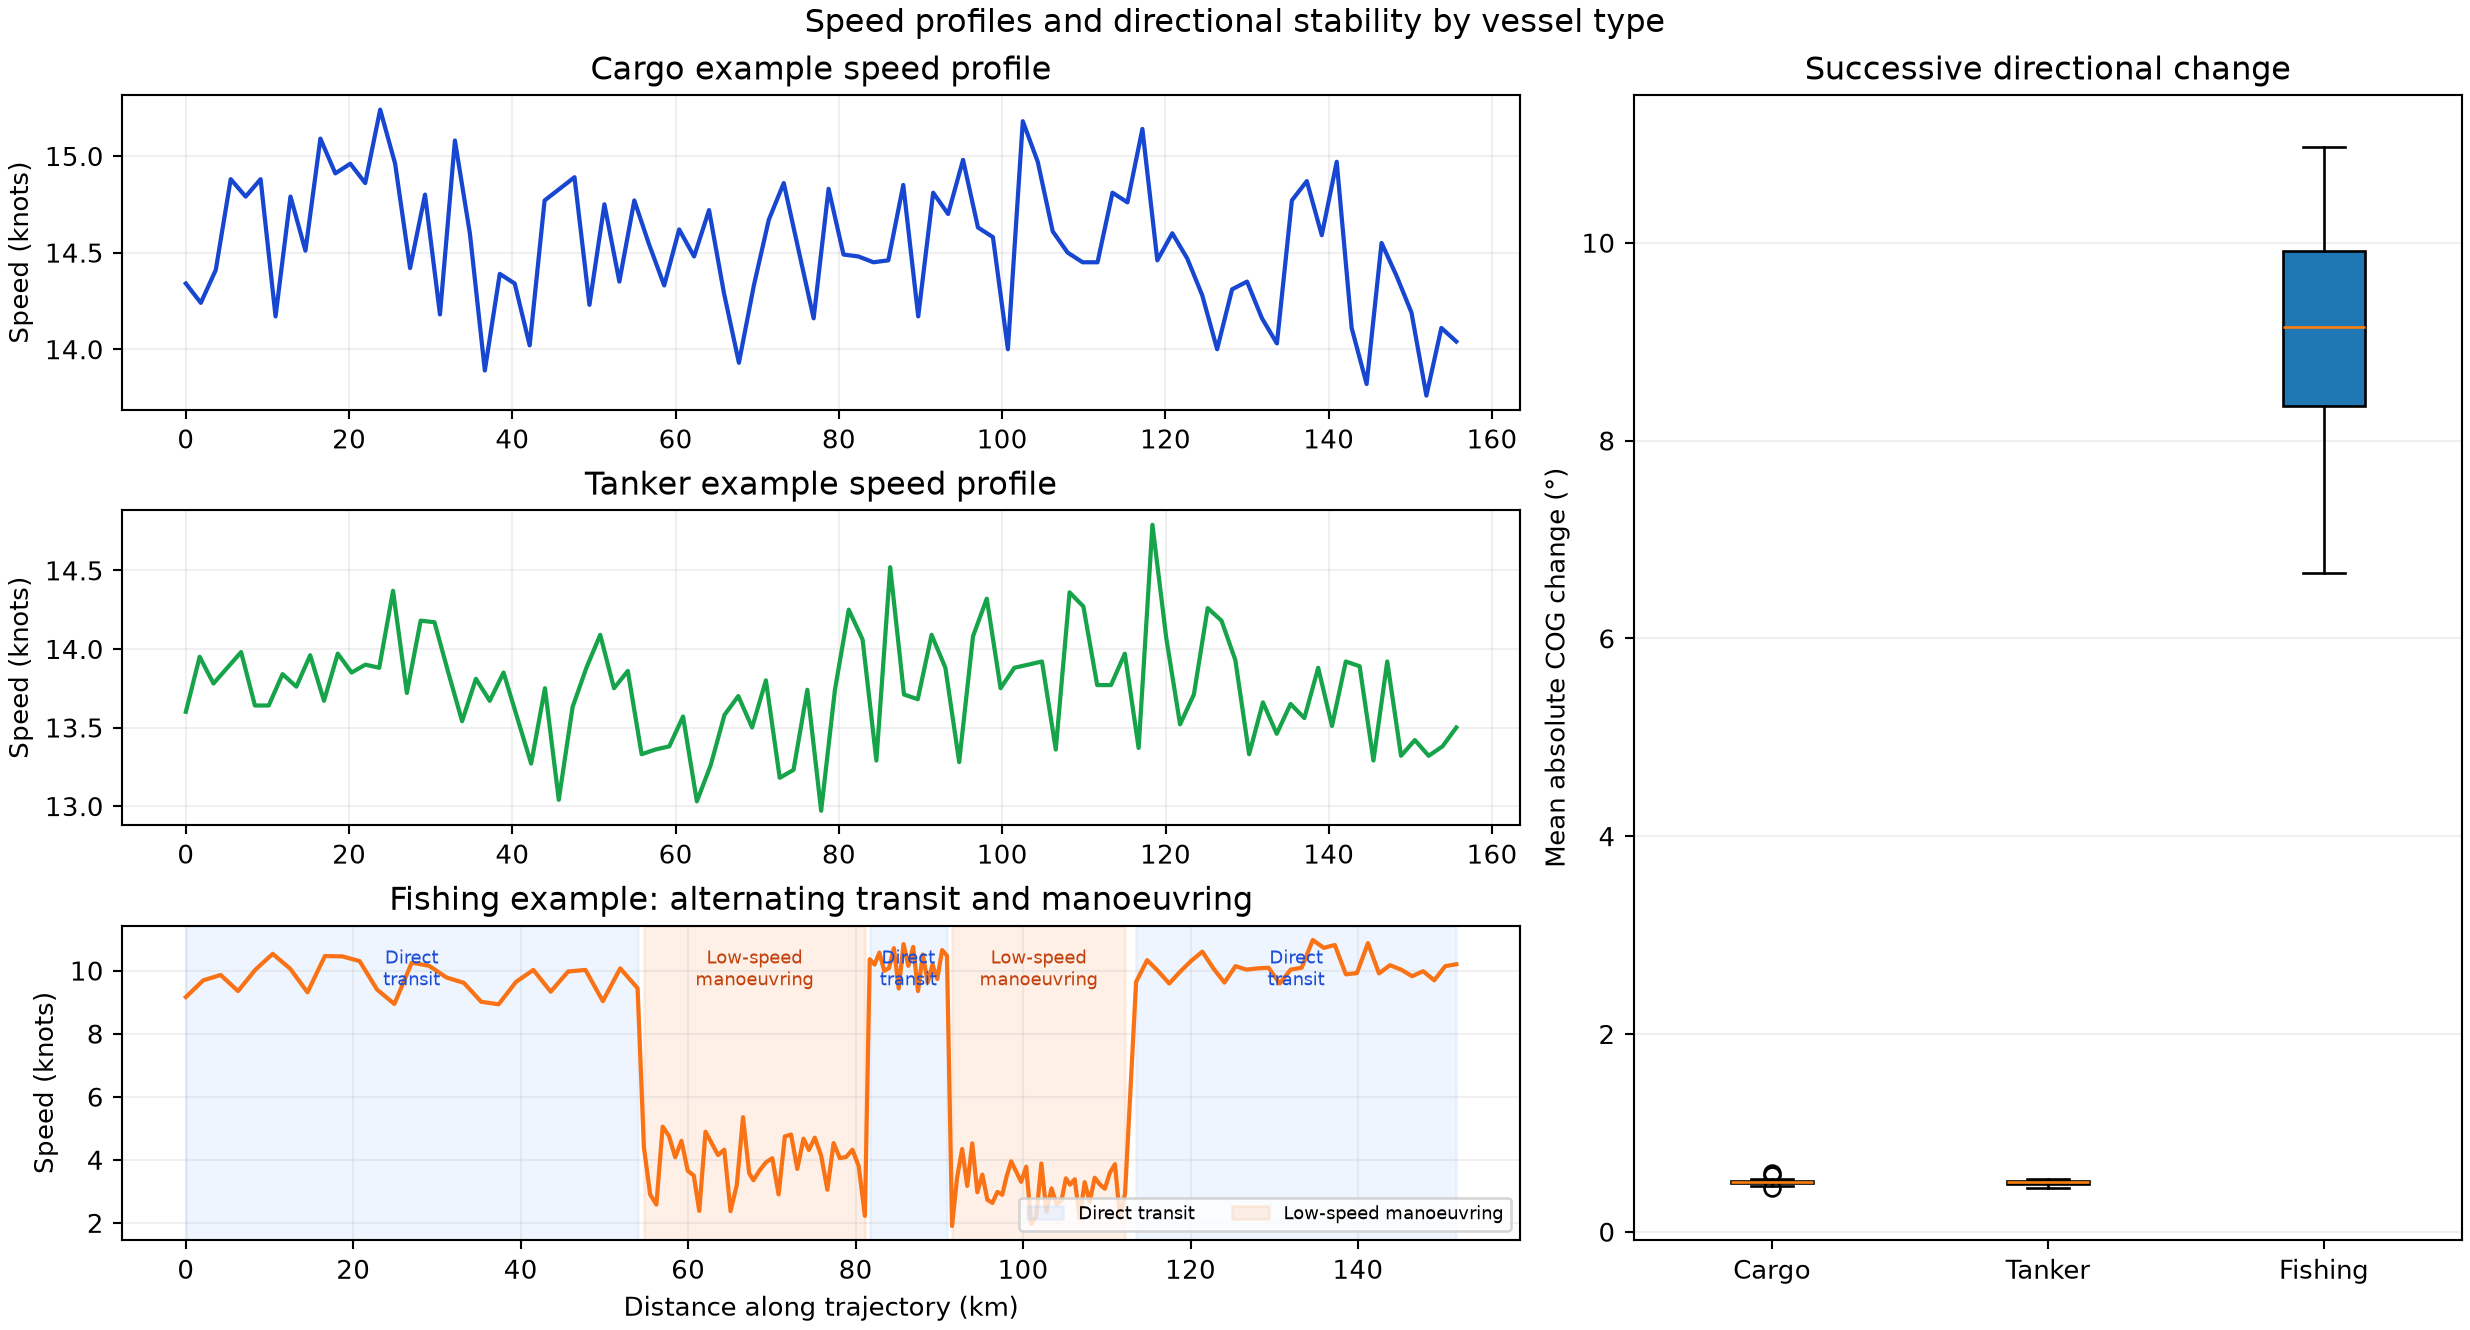

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on="vessel_id"); print(df.groupby(["ship_type","trajectory_id"]).sog_knots.std().groupby(level=0).describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_direction_by_type.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "type_speed_direction_dynamics",
  "insight": "Fishing trajectories alternate between direct transit and low-speed manoeuvring, while cargo and tanker trajectories remain more stable in speed and direction.",
  "insight_value": {
    "median_mean_speed_knots": {
      "Cargo": 14.43,
      "Fishing": 6.89,
      "Tanker": 13.0
    },
    "median_speed_sd_knots": {
      "Cargo": 0.34,
      "Fishing": 3.32,
      "Tanker": 0.34
    },
    "median_direction_change_deg": {
      "Cargo": 0.5,
      "Fishing": 9.15,
      "Tanker": 0.5
    },
    "median_fishing_speed_by_status_knots": {
      "Under way fishing": 3.61,
      "Under way using engine": 9.92
    },
    "fishing_status_sequence": [
      "Under way using engine",
      "Under way fishing",
      "Under way using engine",
      "Under way fishing",
      "Under way using engine"
    ],
    "fishing_status_transitions_per_trajectory": 4
  },
  "plot": {
    "plot_type": "representative_speed_profiles_and_direction_distribution",
    "title": "Speed and Direction Dynamics by Type",
    "file": "visualizations/speed_direction_by_type.png",
    "description": "Show the actual five-stage fishing status sequence along trajectory distance and compare trajectory-level successive COG changes across vessel types."
  },
  "question": "How do speed and direction dynamics differ among vessel types?",
  "actionable_insight": "Show the actual five-stage fishing status sequence along trajectory distance and compare trajectory-level successive COG changes across vessel types.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on=\"vessel_id\"); print(df.groupby([\"ship_type\",\"trajectory_id\"]).sog_knots.std().groupby(level=0).describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "point_speed",
    "course_over_ground",
    "navigation_status",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: How is vessel type associated with trajectory recurrence?

#### Analysis action

Overlay three voyages from one fishing vessel to show partial spatial recurrence together with shifts to other working locations, then compare the share of vessels with at least one revisited local region across vessel types.

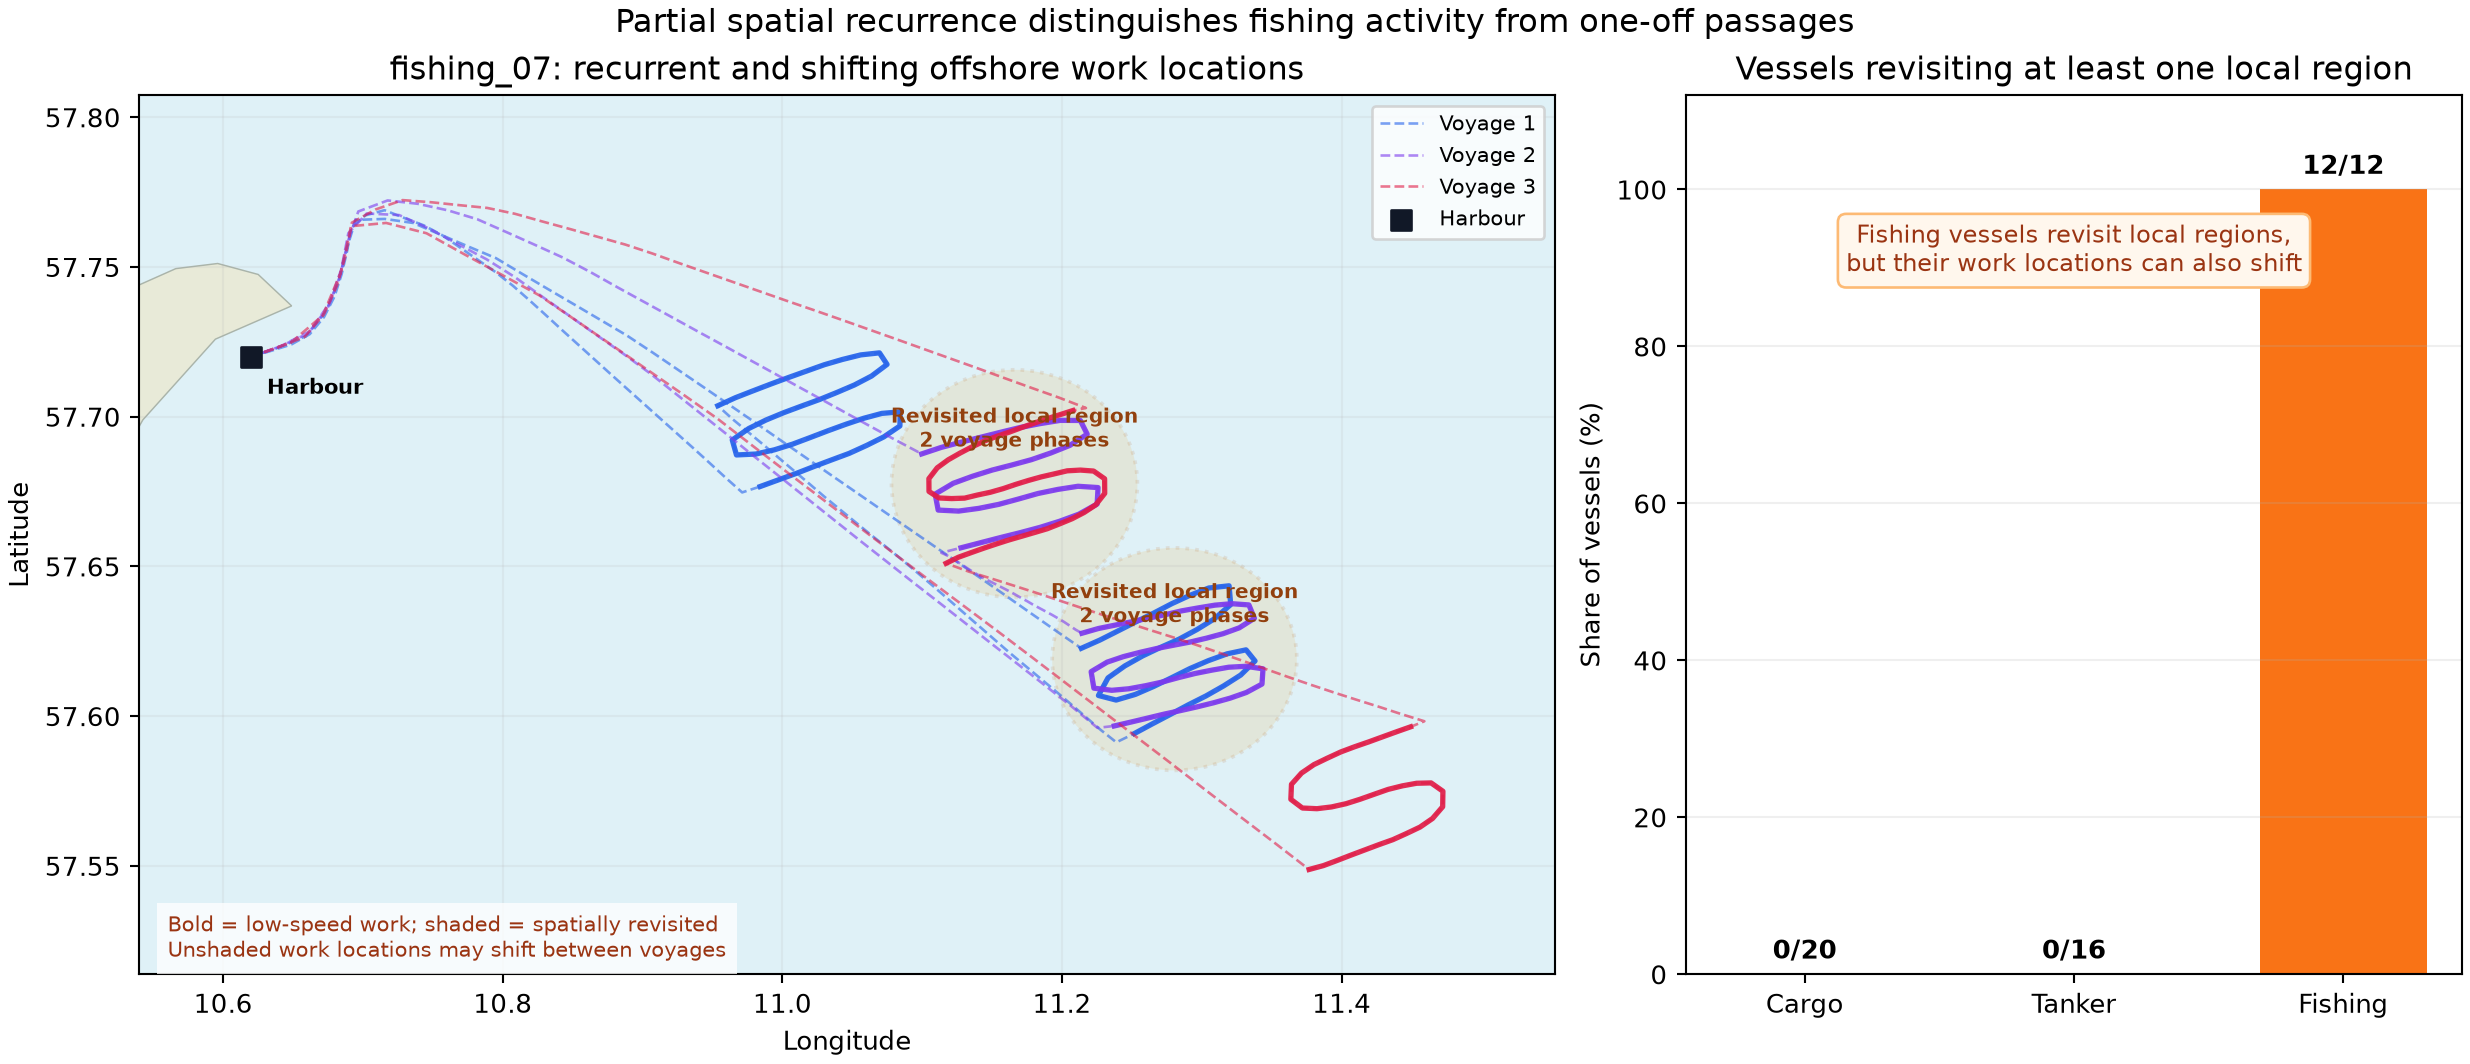

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on="vessel_id"); print(df.groupby(["ship_type","vessel_id"]).trajectory_id.nunique().describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/trajectory_recurrence_by_type.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "type_trajectory_recurrence",
  "insight": "Vessel type is associated with trajectory recurrence: fishing vessels frequently revisit the same local operating areas, while cargo and tanker vessels are more likely to pass through without repeated local movements.",
  "insight_value": {
    "median_repeated_fishing_route_dispersion_km": 4.77,
    "vessels_revisiting_local_areas": {
      "Cargo": 0,
      "Tanker": 0,
      "Fishing": 12
    },
    "total_vessels_by_type": {
      "Cargo": 20,
      "Fishing": 12,
      "Tanker": 16
    },
    "working_region_count_range_across_fishing_vessels": [
      2,
      4
    ],
    "fishing_vessels_with_shifted_working_regions": 9,
    "passage_vessels_with_repeated_local_movements": 0
  },
  "plot": {
    "plot_type": "revisited_working_region_map_and_revisit_rate",
    "title": "Repeated-region Visits by Vessel Type",
    "file": "visualizations/trajectory_recurrence_by_type.png",
    "description": "Overlay three voyages from one fishing vessel to show partial spatial recurrence together with shifts to other working locations, then compare the share of vessels with at least one revisited local region across vessel types."
  },
  "question": "How is vessel type associated with trajectory recurrence?",
  "actionable_insight": "Overlay three voyages from one fishing vessel to show partial spatial recurrence together with shifts to other working locations, then compare the share of vessels with at least one revisited local region across vessel types.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on=\"vessel_id\"); print(df.groupby([\"ship_type\",\"vessel_id\"]).trajectory_id.nunique().describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "ship_type",
    "gps_position",
    "trajectory_timestamp",
    "point_speed",
    "navigation_status"
  ]
}

### Summary of Findings (Flag 20)

Cargo and tanker vessels mainly make long, continuous passages across the area, while fishing vessels repeatedly remain within smaller local operating regions before continuing their trips. Fishing trajectories alternate between direct transit and low-speed manoeuvring, while cargo and tanker trajectories remain more stable in speed and direction. Vessel type is associated with trajectory recurrence: fishing vessels frequently revisit the same local operating areas, while cargo and tanker vessels are more likely to pass through without repeated local movements.